In [1]:
from astroquery.mast import Observations
from astropy.io import fits

In [2]:
ob = Observations.query_criteria(target_name=368788781
                                ,sequence_number=51
                                ,provenance_name="SPOC")
prod = Observations.get_product_list(ob)
lc = Observations.download_products(prod, productSubGroupDescription="LC")
fits_path = lc['Local Path'][0]

In [3]:
fits.info(fits_path)

Filename: ./mastDownload/TESS/tess2022112184951-s0051-0000000368788781-0223-s/tess2022112184951-s0051-0000000368788781-0223-s_lc.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      44   ()      
  1  LIGHTCURVE    1 BinTableHDU    167   17707R x 20C   [D, E, J, E, E, E, E, E, E, J, D, E, D, E, D, E, D, E, E, E]   
  2  APERTURE      1 ImageHDU        49   (11, 43)   int32   


In [8]:
with fits.open(fits_path) as hdulist:
    timedel = hdulist[1].header['TIMEDEL']

In [9]:
import astropy.units as u

In [14]:
timedel*u.day.to(u.min)

2.0

0.001388888888888889

In [9]:
%load_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
from classed_pipeline import LC
lc = LC(442871031, 32, 'spoc-lc')
lc.timedel

INFO: Found cached file ./mastDownload/TESS/tess2020324010417-s0032-0000000442871031-0200-s/tess2020324010417-s0032-0000000442871031-0200-s_lc.fits with expected size 1903680. [astroquery.query]


<Quantity 0.00138889 d>

posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values


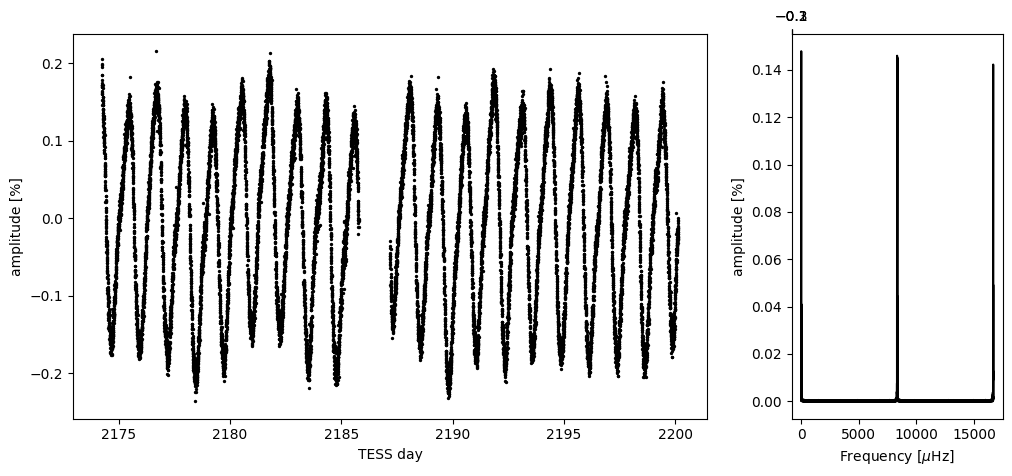

In [11]:
lc.make_plots()

In [8]:
np.linspace(lc.timedel, lc.timedel*100, 100)

<Quantity [0.00138889, 0.00277778, 0.00416667, 0.00555556, 0.00694444,
           0.00833333, 0.00972222, 0.01111111, 0.0125    , 0.01388889,
           0.01527778, 0.01666667, 0.01805556, 0.01944444, 0.02083333,
           0.02222222, 0.02361111, 0.025     , 0.02638889, 0.02777778,
           0.02916667, 0.03055556, 0.03194444, 0.03333333, 0.03472222,
           0.03611111, 0.0375    , 0.03888889, 0.04027778, 0.04166667,
           0.04305556, 0.04444444, 0.04583333, 0.04722222, 0.04861111,
           0.05      , 0.05138889, 0.05277778, 0.05416667, 0.05555556,
           0.05694444, 0.05833333, 0.05972222, 0.06111111, 0.0625    ,
           0.06388889, 0.06527778, 0.06666667, 0.06805556, 0.06944444,
           0.07083333, 0.07222222, 0.07361111, 0.075     , 0.07638889,
           0.07777778, 0.07916667, 0.08055556, 0.08194444, 0.08333333,
           0.08472222, 0.08611111, 0.0875    , 0.08888889, 0.09027778,
           0.09166667, 0.09305556, 0.09444444, 0.09583333, 0.09722222,
      

In [6]:
import numpy as np

In [17]:
(1/(14*u.day)).to(u.microhertz)

<Quantity 0.82671958 uHz>

In [11]:
from astropy import units as u

In [2]:
cd ./pipeline

/Users/tdutkiewicz/forks/TESS-JWST-cal-stars/pipeline


INFO: Found cached file ./mastDownload/TESS/tess2019331140908-s0019-0000000327587572-0164-s/tess2019331140908-s0019-0000000327587572-0164-s_lc.fits with expected size 1834560. [astroquery.query]


/Users/tdutkiewicz/miniconda3/envs/nb/lib/python3.11/site-packages/astropy/units/quantity.py:673: RuntimeWarning: invalid value encountered in sqrt
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


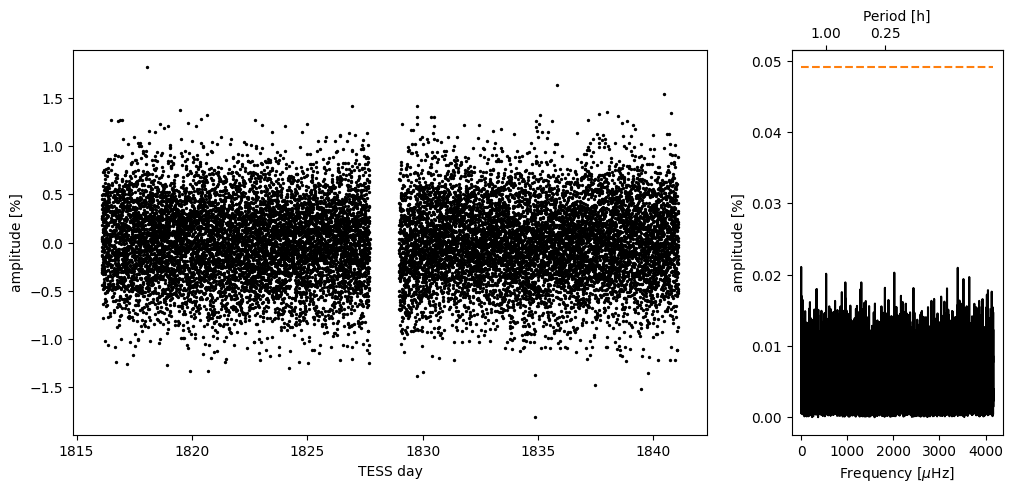

In [7]:
from astroquery.mast import Observations
from astropy import units as u
from astropy.io import fits
from astropy.timeseries import LombScargle

import matplotlib.pyplot as plt
import numpy as np

# Name should indicate that it contains data from one target for one sector only
class LC:
    # Initialize with TIC ID, sector, and data source
    def __init__(self, tid, sector, source):
        self.tid = tid
        self.sector = sector
        if source not in ["spoc-lc", "ffi-lc", "ffi-only"]:
            raise AttributeError(f"source must be one of ['spoc-lc', 'ffi-lc', 'ffi-only'], input was \"{source}\"")
        self.source = source
        self.fits = self.get_fits_path()
        self.times, self.flux, self.flux_err, self.timedel, self.elapsed= self.parse_quality()
        self.freqs, self.pwrs, self.sigma3 = self.make_pgrm()

    def get_fits_path(self):
        ''' Using the TIC ID, sector, and source, download the file
        '''
        if self.source == "spoc-lc":
            ob = Observations.query_criteria(target_name=self.tid
                                             ,sequence_number=self.sector
                                             ,provenance_name="SPOC")
        elif self.source == "ffi-lc":
            ob = Observations.query_criteria(target_name=self.tid
                                             ,sequence_number=self.sector
                                             ,provenance_name="TESS-SPOC")
        # TO-DO: how will we support FFIs?
        prod = Observations.get_product_list(ob)
        lc = Observations.download_products(prod, productSubGroupDescription="LC")
        fits_path = lc['Local Path'][0]
        return fits_path

    def parse_quality(self):
        ''' Read in a fits path, output the times / fluxes
        (remove the "bad quality" values from both)
        Also remove NaNs, or else we can't generate periodograms
        '''
        # Open file, read in the times, SAP flux, quality flags, and cadence
        with fits.open(self.fits, mode="readonly") as hdulist:
            tmz = hdulist[1].data['TIME']*u.day
            pdc_fluxes = hdulist[1].data['PDCSAP_FLUX']
            quality = hdulist[1].data['QUALITY']
            pdc_error = hdulist[1].data['PDCSAP_FLUX_ERR']
            timedel = hdulist[1].header['TIMEDEL']*u.day
            elapse = hdulist[1].header['TELAPSE']*u.day
        # Convert flags to binary
        bad_bits = np.array([1,2,3,4,5,6,8,10,12,13,15])
        value = 0
        for v in bad_bits:
            value = value + 2**(v-1)
        
        # "bad data" will match the quality flags
        bad_quality = np.bitwise_and(quality, value) >= 1
        
        # Include any NaNs in bad data, 
        nan_data = np.isnan(pdc_fluxes)
        
        # Concat bad quality and NaN indexes
        bad_data = np.logical_or(bad_quality, nan_data)

        return tmz[~bad_data], pdc_fluxes[~bad_data], pdc_error[~bad_data], timedel, elapse
    
    def make_pgrm(self):
        t = self.times
        # Normalize these values
        f_norm = self.flux/np.median(self.flux)
        f_err = self.flux_err/np.median(self.flux_err)
        
        # Nyquist limits
        max_f = (1/(2*self.timedel)).to(u.microhertz)
        min_f = (2/self.elapsed).to(u.microhertz)
        samples = int(5*self.elapsed*max_f)
        freqs = np.linspace(min_f, max_f, samples)
        
        # do psd lombscargle
        LS = LombScargle(t, f_norm, normalization='psd')
        pwrs = LS.power(freqs)
        max_p = max(pwrs)
        
        # get false alarm probability for maximum peak
        LS_err = LombScargle(t, f_norm, f_err, normalization='psd')
        max_pwr_err = LS_err.power(freqs).max()
        sigma3 = float(LS_err.false_alarm_level(0.997))*max_p/max_pwr_err
        
        # special correction to convert to amplitude
        pwrs = np.sqrt(pwrs) * np.sqrt(4.0 / len(t))
        sigma3 = np.sqrt(sigma3) * np.sqrt(4.0 / len(t))
        return freqs, pwrs, sigma3
    
    def make_plots(self):
        f_norm = self.flux/np.nanmedian(self.flux)
        fig, (ax1,ax2) = plt.subplots(1,2, figsize=(12,5), gridspec_kw={'width_ratios':[3,1]})
        # plot lc
        ax1.scatter(self.times ,(f_norm-1)*100 ,c='black',s=2)
        ax1.set_xlabel('TESS day')
        ax1.set_ylabel('amplitude [%]')
        
        # plot prgm
        ax2.plot(self.freqs, self.pwrs*100, c='black')
        ax2.set_xlabel('Frequency [$\mu$Hz]')
        ax2.set_ylabel('amplitude [%]')
        ax2.hlines(self.sigma3, self.freqs[0].value, self.freqs[-1].value, linestyles='dashed', colors='tab:orange')
        
        # Set up period at top
        def invert(x):
            # 1/x with special treatment of x == 0
            x = np.array(x).astype(float)
            near_zero = np.isclose(x, 0)
            x[near_zero] = np.inf
            x[~near_zero] = 277.77778 / x[~near_zero]
            return np.around(x, decimals=1)
        per_ax2 = ax2.secondary_xaxis('top', functions=(invert, invert))
        per_ax2.set_xticks([1, 0.25])
        per_ax2.set_xlabel('Period [h]')
    
    def get_stats(self):
        # No variability detected
        if self.sigma3 > max(self.pwrs*100):
            # Maximum amplitude under one day
            m1d = max(self.pwrs[np.argwhere(lc.freqs>11.574*u.microhertz)])
            # Envelope containing 99.7% of the data
            v99 = np.nanpercentile(self.flux/np.nanmedian(self.flux), 99.865) - np.nanpercentile(self.flux/np.nanmedian(self.flux), 0.135)
            print(f"No variability detected\nm1d: {m1d}\nv99 {v99}")
        else:
            max_amp = max(self.pwrs)
            max_freq = self.freqs[np.argwhere(self.pwrs==max_amp)]
            max_per = (1/max_freq).to(u.day)
            print(f"Max freq: {max_freq} = {max_per}\n Amp @ max period: {max_amp*100}")
            
lc = LC(327587572, 19, 'spoc-lc')
lc.make_plots()

In [8]:
lc.get_stats()

No variability detected
m1d: [0.00020972]
v99 0.024724255195260114


In [94]:
lc.sigma3#max(lc.pwrs)*100

<Quantity 0.04908741>

## Standard Deviation
Expressing in amplitude/percent so my brain doesn't melt

In [54]:
std = np.std(lc.flux/np.nanmedian(lc.flux)*100)
print(std, std*3)

0.407625 1.2228749692440033


The "gaussian error carry through" implemented by astropy gives a threshold which is much higher, at ~0.05%

In [3]:
lc2 = LC(442871031, 32, 'spoc-lc')

INFO: Found cached file ./mastDownload/TESS/tess2020324010417-s0032-0000000442871031-0200-s/tess2020324010417-s0032-0000000442871031-0200-s_lc.fits with expected size 1903680. [astroquery.query]


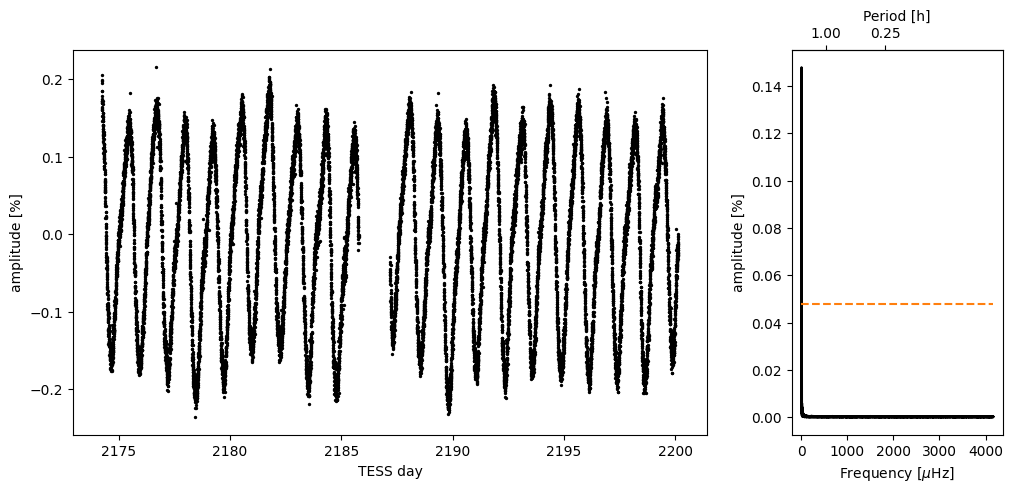

In [4]:
lc2.make_plots()

In [6]:
type(lc2.get_stats())

Max freq: [[9.17058853]] uHz = [[1.26208629]] d
 Amp @ max period: 0.14785755667945427


NoneType

In [86]:
max(lc2.pwrs)*100

<Quantity 0.14785756>

In [85]:
lc2.sigma3

<Quantity 0.04801669>

In [9]:
Lc3 = LC(219752116, 40, 'spoc-lc')

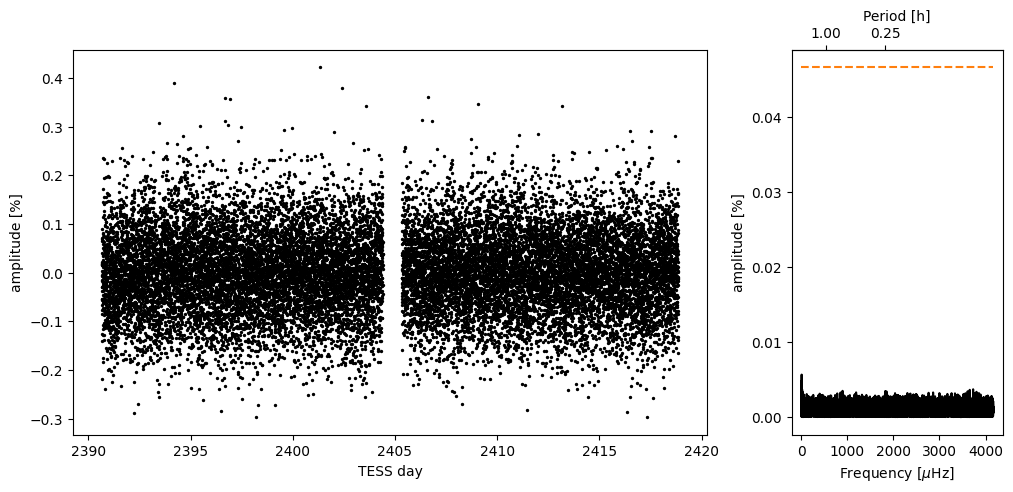

In [10]:
Lc3.make_plots()

In [11]:
Lc3.get_stats()

No variability detected
m1d: [5.68629551e-05]
v99 0.005094037273526308


In [13]:
from astroquery.mast import Observations
from astropy import units as u
from astropy.io import fits
from astropy.timeseries import LombScargle

import matplotlib.pyplot as plt
import numpy as np


class LC:
    # Initialize with TIC ID, sector, and data source
    def __init__(self, tid, sector, source):
        self.tid = tid
        self.sector = sector
        if source not in ["spoc-lc", "ffi-lc", "ffi-only"]:
            raise AttributeError(f"source must be one of ['spoc-lc', 'ffi-lc', 'ffi-only'], input was \"{source}\"")
        self.source = source
        self.get_fits_path()
        self.times, self.flux, self.flux_err, self.timedel, self.elapsed= self.parse_quality()
        self.freqs, self.pwrs, self.sigma3 = self.make_pgrm()

    def get_fits_path(self):
        ''' Using the TIC ID, sector, and source, download the file
        '''
        if self.source == "spoc-lc":
            ob = Observations.query_criteria(target_name=self.tid
                                             ,sequence_number=self.sector
                                             ,provenance_name="SPOC")
        elif self.source == "ffi-lc":
            ob = Observations.query_criteria(target_name=self.tid
                                             ,sequence_number=self.sector
                                             ,provenance_name="TESS-SPOC")
        # TO-DO: how will we support FFIs?
        prod = Observations.get_product_list(ob)
        lc = Observations.download_products(prod, productSubGroupDescription="LC")
        fits_path = lc['Local Path'][0]
        self.fits = fits_path
        #return fits_path

    def parse_quality(self):
        ''' Read in a fits path, output the times / fluxes
        (remove the "bad quality" values from both)
        Also remove NaNs, or else we can't generate periodograms
        '''
        # Open file, read in the times, SAP flux, quality flags, and cadence
        with fits.open(self.fits, mode="readonly") as hdulist:
            tmz = hdulist[1].data['TIME']*u.day
            pdc_fluxes = hdulist[1].data['PDCSAP_FLUX']
            quality = hdulist[1].data['QUALITY']
            pdc_error = hdulist[1].data['PDCSAP_FLUX_ERR']
            timedel = hdulist[1].header['TIMEDEL']*u.day
            elapse = hdulist[1].header['TELAPSE']*u.day
        # Convert flags to binary
        bad_bits = np.array([1,2,3,4,5,6,8,10,12,13,15])
        value = 0
        for v in bad_bits:
            value = value + 2**(v-1)
        
        # "bad data" will match the quality flags
        bad_quality = np.bitwise_and(quality, value) >= 1
        
        # Include any NaNs in bad data, 
        nan_data = np.isnan(pdc_fluxes)
        
        # Concat bad quality and NaN indexes
        bad_data = np.logical_or(bad_quality, nan_data)

        return tmz[~bad_data], pdc_fluxes[~bad_data], pdc_error[~bad_data], timedel, elapse
    
    def make_pgrm(self):
        t = self.times
        # Normalize these values
        f_norm = self.flux/np.median(self.flux)
        f_err = self.flux_err/np.median(self.flux_err)
        
        # Nyquist limits
        max_f = (1/(2*self.timedel)).to(u.microhertz)
        min_f = (2/self.elapsed).to(u.microhertz)
        samples = int(5*self.elapsed*max_f)
        freqs = np.linspace(min_f, max_f, samples)
        
        # do psd lombscargle
        LS = LombScargle(t, f_norm, normalization='psd')
        pwrs = LS.power(freqs)
        max_p = max(pwrs)
        
        # get false alarm probability for maximum peak
        LS_err = LombScargle(t, f_norm, f_err, normalization='psd')
        max_pwr_err = LS_err.power(freqs).max()
        sigma3 = float(LS_err.false_alarm_level(0.997))*max_p/max_pwr_err
        
        # special correction to convert to amplitude
        pwrs = np.sqrt(pwrs) * np.sqrt(4.0 / len(t))
        sigma3 = np.sqrt(sigma3) * np.sqrt(4.0 / len(t))
        return freqs, pwrs, sigma3
    
    def make_plots(self):
        f_norm = self.flux/np.nanmedian(self.flux)
        fig, (ax1,ax2) = plt.subplots(1,2, figsize=(12,5), gridspec_kw={'width_ratios':[3,1]})
        # plot lc
        ax1.scatter(self.times ,(f_norm-1)*100 ,c='black',s=2)
        ax1.set_xlabel('TESS day')
        ax1.set_ylabel('amplitude [%]')
        
        # plot prgm
        ax2.plot(self.freqs, self.pwrs*100, c='black')
        ax2.set_xlabel('Frequency [$\mu$Hz]')
        ax2.set_ylabel('amplitude [%]')
        ax2.hlines(self.sigma3, self.freqs[0].value, self.freqs[-1].value, linestyles='dashed', colors='tab:orange')
        
        # Set up period at top
        def invert(x):
            # 1/x with special treatment of x == 0
            x = np.array(x).astype(float)
            near_zero = np.isclose(x, 0)
            x[near_zero] = np.inf
            x[~near_zero] = 277.77778 / x[~near_zero]
            return np.around(x, decimals=1)
        per_ax2 = ax2.secondary_xaxis('top', functions=(invert, invert))
        per_ax2.set_xticks([1, 0.25])
        per_ax2.set_xlabel('Period [h]')
    
    def get_stats(self):
        # No variability detected
        if self.sigma3 > max(self.pwrs*100):
            # Maximum amplitude under one day
            m1d = max(self.pwrs[np.argwhere(lc.freqs>11.574*u.microhertz)])
            # Envelope containing 99.7% of the data
            v99 = np.nanpercentile(self.flux/np.nanmedian(self.flux), 99.865) - np.nanpercentile(self.flux/np.nanmedian(self.flux), 0.135)
            print(f"Bro, no variability detected\nm1d: {m1d}\nv99 {v99}")
        else:
            max_amp = max(self.pwrs)
            max_freq = self.freqs[np.argwhere(self.pwrs==max_amp)]
            max_per = (1/max_freq).to(u.day)
            print(f"Max freq: {max_freq} = {max_per}\n Amp @ max period: {max_amp*100}")
            
lc = LC(327587572, 19, 'spoc-lc')
lc.get_stats()

INFO: Found cached file ./mastDownload/TESS/tess2019331140908-s0019-0000000327587572-0164-s/tess2019331140908-s0019-0000000327587572-0164-s_lc.fits with expected size 1834560. [astroquery.query]


/Users/tdutkiewicz/miniconda3/envs/nb/lib/python3.11/site-packages/astropy/units/quantity.py:673: RuntimeWarning: invalid value encountered in sqrt
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


Bro, no variability detected
m1d: [0.00020972]
v99 0.024724255195260114


In [14]:
obs = Observations.query_criteria(target_name=327587572,provenance_name="SPOC")

In [15]:
obs

intentType,obs_collection,provenance_name,instrument_name,project,filters,wavelength_region,target_name,target_classification,sequence_number,obs_id,s_ra,s_dec,proposal_id,proposal_pi,dataproduct_type,calib_level,t_min,t_max,t_exptime,em_min,em_max,obs_title,t_obs_release,proposal_type,dataRights,mtFlag,obsid,objID
str7,str4,str4,str10,str4,str4,str7,str9,str1,int64,str52,float64,float64,str23,str14,str10,int64,float64,float64,float64,float64,float64,str1,float64,str1,str6,bool,str9,str9
science,TESS,SPOC,Photometer,TESS,TESS,Optical,327587572,--,19,tess2019331140908-s0019-0000000327587572-0164-s,76.3775761608797,52.8310891101113,G022077_G022028_G022017,"Ricker, George",timeseries,3,58815.58771973,58840.65165764,120.0,600.0,1000.0,--,58875.0,--,PUBLIC,False,27701644,70986247
science,TESS,SPOC,Photometer,TESS,TESS,Optical,327587572,--,59,tess2022330142927-s0059-0000000327587572-0248-a_fast,76.3775761608797,52.8310891101113,G05084_G05115_G05152,"Ricker, George",timeseries,3,59909.76770690972,59936.192104421294,20.0,600.0,1000.0,--,59962.0,--,PUBLIC,False,113393069,210502372
science,TESS,SPOC,Photometer,TESS,TESS,Optical,327587572,--,59,tess2022330142927-s0059-0000000327587572-0248-s,76.3775761608797,52.8310891101113,G05084_G05115_G05152,"Ricker, George",timeseries,3,59909.77048474537,59936.19140998842,120.0,600.0,1000.0,--,59962.0,--,PUBLIC,False,113393074,210502381
